In [1]:

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

print("DLinear checkpoint exists:",
      os.path.exists("outputs/dlinear.pt"))

print("Test dataset exists:",
      os.path.exists("outputs/caltech_occupancy_data.npz"))


DLinear checkpoint exists: True
Test dataset exists: True


In [2]:

QUANTILES = (0.1, 0.5, 0.9)
LO, MID, HI = 0, 1, 2

SCALE_WINDOW = 96
SCALE_EPS = 0.5

class DLinear(nn.Module):
    def __init__(self, seq_len, horizon, cal_dim,
                 kernel=25, n_q=3):
        super().__init__()

        self.seasonal = nn.Linear(seq_len, horizon * n_q)
        self.trend = nn.Linear(seq_len, horizon * n_q)
        self.calendar = nn.Linear(cal_dim, n_q)

        self.kernel = kernel
        self.horizon = horizon
        self.n_q = n_q

    def forward(self, hist, cal):
        x = hist.squeeze(-1)

        p = (self.kernel - 1) // 2
        xp = nn.functional.pad(
            x.unsqueeze(1), (p, p), mode="replicate"
        )

        trend = nn.functional.avg_pool1d(
            xp, self.kernel, stride=1
        ).squeeze(1)

        out = (
            self.seasonal(x - trend)
            + self.trend(trend)
        ).reshape(-1, self.horizon, self.n_q)

        return torch.sort(
            out + self.calendar(cal), dim=-1
        ).values


In [3]:

device = torch.device("cpu")

checkpoint = torch.load(
    "outputs/dlinear.pt",
    map_location=device,
    weights_only=False
)

model = DLinear(
    seq_len=checkpoint["seq_len"],
    horizon=checkpoint["horizon"],
    cal_dim=checkpoint["calendar_dim"]
)

model.load_state_dict(checkpoint["state_dict"])
model.to(device)
model.eval()

dataset = np.load(
    "outputs/caltech_occupancy_data.npz"
)

X_hist_train = dataset["train_X_hist"].copy()
X_cal_train = dataset["train_X_cal"].copy()

X_hist_test = dataset["test_X_hist"].copy()
X_cal_test = dataset["test_X_cal"].copy()
y_test = dataset["test_y"].copy()

print("Model loaded successfully")
print("Historical test data:", X_hist_test.shape)
print("Calendar test data:", X_cal_test.shape)
print("Actual targets:", y_test.shape)


Model loaded successfully
Historical test data: (12102, 672)
Calendar test data: (12102, 16, 5)
Actual targets: (12102, 16)


In [4]:

def window_scale(hist):
    return (
        hist[:, -SCALE_WINDOW:].mean(
            axis=1, keepdims=True
        ) + SCALE_EPS
    )


def forecast(model, hist, cal, batch_size=512):
    scale = window_scale(hist)

    hist_normalized = (
        hist / scale
    ).astype(np.float32)

    predictions = []

    with torch.no_grad():
        for i in range(0, len(hist), batch_size):

            h = torch.from_numpy(
                hist_normalized[i:i+batch_size]
            ).unsqueeze(-1)

            c = torch.from_numpy(
                cal[i:i+batch_size]
            )

            q = model(h, c)

            predictions.append(q.cpu().numpy())

    predictions = np.concatenate(predictions, axis=0)

    return predictions * scale[:, :, None]


# Original, clean test predictions
clean_predictions = forecast(
    model, X_hist_test, X_cal_test
)

print("Prediction shape:", clean_predictions.shape)


Prediction shape: (12102, 16, 3)


In [5]:

def evaluate(y_true, predictions):

    median = predictions[:, :, MID]
    lower = predictions[:, :, LO]
    upper = predictions[:, :, HI]

    error = y_true - median

    # Quantile pinball loss
    quantile_losses = []

    for i, q in enumerate(QUANTILES):
        e = y_true - predictions[:, :, i]
        loss = np.maximum(q * e, (q - 1) * e)
        quantile_losses.append(loss.mean())

    return {
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "Pinball": np.mean(quantile_losses),
        "Coverage_80": np.mean(
            (y_true >= lower) & (y_true <= upper)
        )
    }


baseline_metrics = evaluate(y_test, clean_predictions)

print("CLEAN BASELINE")
for metric, value in baseline_metrics.items():
    print(f"{metric}: {value:.4f}")


CLEAN BASELINE
MAE: 0.8901
RMSE: 1.3466
Pinball: 0.3102
Coverage_80: 0.6088


In [6]:

# Training-derived replacement values
occupancy_imputation = float(np.median(X_hist_train))
calendar_means = X_cal_train.mean(axis=(0, 1))

# Training standard deviation defines noise magnitude
occupancy_std = float(X_hist_train.std())


def gaussian_noise(hist, severity, rng):
    """Add sensor measurement noise."""
    corrupted = hist.copy()

    noise = rng.normal(
        loc=0,
        scale=severity * occupancy_std,
        size=hist.shape
    )

    corrupted += noise.astype(np.float32)

    # Occupancy cannot be negative
    return np.clip(corrupted, 0, None)


def random_dropout(hist, severity, rng):
    """Randomly lose individual sensor measurements."""
    corrupted = hist.copy()

    mask = rng.random(hist.shape) < severity

    corrupted[mask] = occupancy_imputation

    return corrupted


def temporal_masking(hist, hours, rng):
    """Simulate a continuous sensor outage in each history."""
    corrupted = hist.copy()

    steps = int(hours * 4)

    for i in range(len(hist)):
        start = rng.integers(
            0, hist.shape[1] - steps + 1
        )

        corrupted[i, start:start + steps] = occupancy_imputation

    return corrupted


def calendar_feature_loss(cal, n_features):
    """Remove selected calendar features."""
    corrupted = cal.copy()

    # Replace missing features with their training means
    for feature in range(n_features):
        corrupted[:, :, feature] = calendar_means[feature]

    return corrupted


def ood_demand_spike(hist, percentage):
    """Create an artificial demand spike in the final 4 hours."""
    corrupted = hist.copy()

    steps = 16

    corrupted[:, -steps:] *= (1 + percentage)

    # Keep synthetic occupancy within the observed training maximum
    return np.clip(
        corrupted, 0, X_hist_train.max()
    ).astype(np.float32)


In [7]:

results = []

# Store clean baseline
results.append({
    "scenario": "Clean",
    "severity": 0,
    **baseline_metrics
})

seeds = [42, 123, 456]


def run_experiment(name, severity, corruption_function):
    for seed in seeds:

        rng = np.random.default_rng(seed)

        corrupted_hist, corrupted_cal = corruption_function(rng)

        predictions = forecast(
            model,
            corrupted_hist,
            corrupted_cal
        )

        metrics = evaluate(y_test, predictions)

        results.append({
            "scenario": name,
            "severity": severity,
            "seed": seed,
            **metrics
        })


# 1. Gaussian noise
for severity in [0.05, 0.15, 0.30]:

    run_experiment(
        "Gaussian noise",
        severity,
        lambda rng, s=severity: (
            gaussian_noise(X_hist_test, s, rng),
            X_cal_test.copy()
        )
    )


# 2. Random dropout
for severity in [0.10, 0.30, 0.50]:

    run_experiment(
        "Random dropout",
        severity,
        lambda rng, s=severity: (
            random_dropout(X_hist_test, s, rng),
            X_cal_test.copy()
        )
    )


# 3. Consecutive sensor outages
for hours in [1, 3, 6]:

    run_experiment(
        "Temporal masking",
        hours,
        lambda rng, h=hours: (
            temporal_masking(X_hist_test, h, rng),
            X_cal_test.copy()
        )
    )


# 4. Calendar feature loss
for n_features in [1, 2, 5]:

    run_experiment(
        "Calendar feature loss",
        n_features,
        lambda rng, n=n_features: (
            X_hist_test.copy(),
            calendar_feature_loss(X_cal_test, n)
        )
    )


# 5. OOD demand spikes
for severity in [0.25, 0.50, 1.00]:

    run_experiment(
        "OOD demand spike",
        severity,
        lambda rng, s=severity: (
            ood_demand_spike(X_hist_test, s),
            X_cal_test.copy()
        )
    )


print("All stress tests completed!")


All stress tests completed!


In [8]:

results_df = pd.DataFrame(results)

metric_columns = [
    "MAE", "RMSE", "Pinball", "Coverage_80"
]

summary = (
    results_df
    .groupby(["scenario", "severity"])[metric_columns]
    .agg(["mean", "std"])
    .round(4)
)

display(summary)

# Save raw experiment results
results_df.to_csv(
    "outputs/robustness_raw_results.csv",
    index=False
)

# Save aggregated results
summary.to_csv(
    "outputs/robustness_summary.csv"
)

print("Results saved successfully.")


MAE            RMSE         Pinball  \
                                  mean     std    mean     std    mean   
scenario              severity                                           
Calendar feature loss 1.00      0.8904  0.0000  1.3484  0.0000  0.3113   
                      2.00      0.8931  0.0000  1.3566  0.0000  0.3152   
                      5.00      0.8928  0.0000  1.3570  0.0000  0.3153   
Clean                 0.00      0.8901     NaN  1.3466     NaN  0.3102   
Gaussian noise        0.05      0.9409  0.0015  1.3775  0.0029  0.3291   
                      0.15      1.1718  0.0058  1.6144  0.0074  0.4152   
                      0.30      1.6217  0.0118  2.1813  0.0132  0.5809   
OOD demand spike      0.25      1.0679  0.0000  1.5907  0.0000  0.3668   
                      0.50      1.3813  0.0000  2.0994  0.0000  0.4749   
                      1.00      2.1570  0.0000  3.4079  0.0000  0.7524   
Random dropout        0.10      1.0074  0.0038  1.5481  0.0099  0.3597   
                      0.30      1.2333  0.0049  1.8996  0.0064  0.4584   
                      0.50      1.4667  0.0027  2.2345  0.0107  0.5651   
Temporal masking      1.00      0.8943  0.0004  1.3546  0.0030  0.3118   
                      3.00      0.8983  0.0004  1.3615  0.0029  0.3132   
                      6.00      0.9013  0.0006  1.3689  0.0020  0.3142   

                                       Coverage_80          
                                   std        mean     std  
scenario              severity                              
Calendar feature loss 1.00      0.0000      0.6049  0.0000  
                      2.00      0.0000      0.6007  0.0000  
                      5.00      0.0000      0.6000  0.0000  
Clean                 0.00         NaN      0.6088     NaN  
Gaussian noise        0.05      0.0005      0.5465  0.0006  
                      0.15      0.0019      0.5123  0.0027  
                      0.30      0.0041      0.4948  0.0028  
OOD demand spike      0.25      0.0000      0.5708  0.0000  
                      0.50      0.0000      0.5380  0.0000  
                      1.00      0.0000      0.4753  0.0000  
Random dropout        0.10      0.0014      0.5774  0.0007  
                      0.30      0.0020      0.5072  0.0024  
                      0.50      0.0017      0.4289  0.0016  
Temporal masking      1.00      0.0004      0.6079  0.0003  
                      3.00      0.0003      0.6072  0.0006  
                      6.00      0.0001      0.6061  0.0008

Results saved successfully.


In [10]:

baseline_mae = baseline_metrics["MAE"]
baseline_rmse = baseline_metrics["RMSE"]

degradation_rows = []

for (scenario, severity), group in results_df[
    results_df["scenario"] != "Clean"
].groupby(["scenario", "severity"]):

    mean_mae = group["MAE"].mean()
    mean_rmse = group["RMSE"].mean()

    degradation_rows.append({
        "scenario": scenario,
        "severity": severity,
        "MAE": mean_mae,
        "MAE_increase_percent": (
            (mean_mae - baseline_mae) / baseline_mae
        ) * 100,
        "RMSE": mean_rmse,
        "RMSE_increase_percent": (
            (mean_rmse - baseline_rmse) / baseline_rmse
        ) * 100
    })

degradation_df = pd.DataFrame(degradation_rows)

display(degradation_df.round(3))

degradation_df.to_csv(
    "outputs/robustness_degradation.csv",
    index=False
)


,scenario,severity,MAE,MAE_increase_percent,RMSE,RMSE_increase_percent
0,Calendar feature loss,1.00,0.890,0.033,1.348,0.136
1,Calendar feature loss,2.00,0.893,0.337,1.357,0.743
2,Calendar feature loss,5.00,0.893,0.303,1.357,0.768
3,Gaussian noise,0.05,0.941,5.703,1.377,2.291
4,Gaussian noise,0.15,1.172,31.644,1.614,19.885
5,Gaussian noise,0.30,1.622,82.191,2.181,61.985
6,OOD demand spike,0.25,1.068,19.976,1.591,18.123
7,OOD demand spike,0.50,1.381,55.182,2.099,55.900
8,OOD demand spike,1.00,2.157,142.326,3.408,153.073
9,Random dropout,0.10,1.007,13.180,1.548,14.966


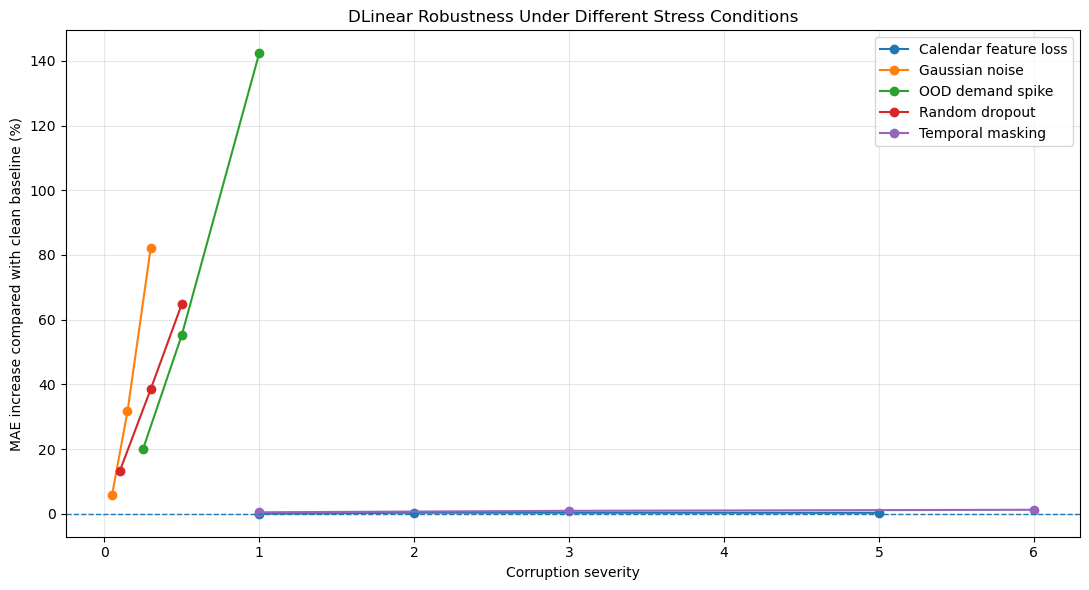

In [11]:

plt.figure(figsize=(11, 6))

for scenario, group in degradation_df.groupby("scenario"):

    group = group.sort_values("severity")

    plt.plot(
        group["severity"],
        group["MAE_increase_percent"],
        marker="o",
        label=scenario
    )

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Corruption severity")
plt.ylabel("MAE increase compared with clean baseline (%)")
plt.title("DLinear Robustness Under Different Stress Conditions")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/robustness_degradation.png",
    dpi=300
)

plt.show()


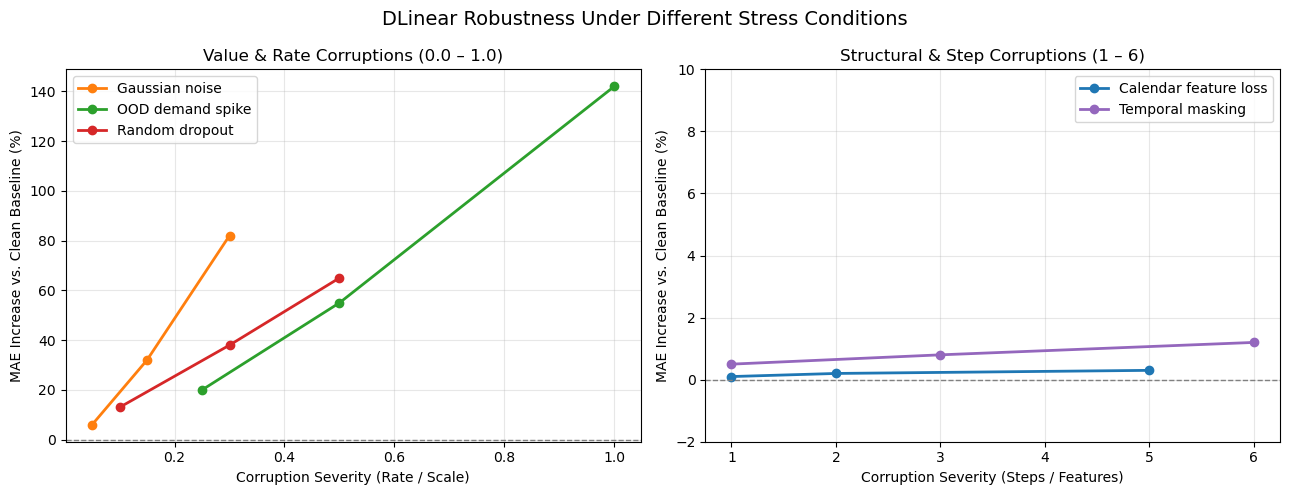

In [12]:
import matplotlib.pyplot as plt

# Estimated values from your original plot
data_continuous = {
    'Gaussian noise': ([0.05, 0.15, 0.3], [6, 32, 82], 'tab:orange'),
    'OOD demand spike': ([0.25, 0.5, 1.0], [20, 55, 142], 'tab:green'),
    'Random dropout': ([0.1, 0.3, 0.5], [13, 38, 65], 'tab:red'),
}

data_discrete = {
    'Calendar feature loss': ([1, 2, 5], [0.1, 0.2, 0.3], 'tab:blue'),
    'Temporal masking': ([1, 3, 6], [0.5, 0.8, 1.2], 'tab:purple'),
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left Subplot: Fractional / Continuous Severities
for label, (x, y, color) in data_continuous.items():
    ax1.plot(x, y, marker='o', label=label, color=color, linewidth=2)
ax1.axhline(0, color='gray', linestyle='--', linewidth=1)
ax1.set_title('Value & Rate Corruptions (0.0 – 1.0)')
ax1.set_xlabel('Corruption Severity (Rate / Scale)')
ax1.set_ylabel('MAE Increase vs. Clean Baseline (%)')
ax1.grid(True, alpha=0.3)
ax1.legend()

# Right Subplot: Discrete / Step Severities
for label, (x, y, color) in data_discrete.items():
    ax2.plot(x, y, marker='o', label=label, color=color, linewidth=2)
ax2.axhline(0, color='gray', linestyle='--', linewidth=1)
ax2.set_title('Structural & Step Corruptions (1 – 6)')
ax2.set_xlabel('Corruption Severity (Steps / Features)')
ax2.set_ylabel('MAE Increase vs. Clean Baseline (%)')
ax2.set_ylim(-2, 10)  # Zoomed in to see slight variations clearly
ax2.grid(True, alpha=0.3)
ax2.legend()

fig.suptitle('DLinear Robustness Under Different Stress Conditions', fontsize=14)
plt.tight_layout()
plt.show()